# Phase 4: PICO Simulation and Scenario Analysis
**GLP-1 RCT Evidence Pipeline**

This notebook runs five scenario analyses on the structured trial database produced in Phase 3:
1. **Data Exploration** — shape, missingness, distributions across all key variables
2. Women-specific evidence landscape
3. Indication landscape (obesity, T2D, cardiovascular, NASH)
4. Comparator gap analysis (head-to-head vs. placebo-only)
5. Outcome heterogeneity analysis (weight loss, HbA1c, MACE)
6. Evidence sufficiency scoring

---
> **Prerequisites:** `glp1_database.xlsx` in the same directory as this notebook (output of Phase 3).

## 0. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 60)
pd.set_option("display.float_format", "{:.1f}".format)

# ── Load database ─────────────────────────────────────────────────────────────
DB_PATH  = "glp1_database.xlsx"   # <- adjust path if needed
DB_SHEET = "All Trials"

df = pd.read_excel(DB_PATH, sheet_name=DB_SHEET)
df.columns = [c.lower().strip().replace(" ", "_") for c in df.columns]

print(f"Loaded {len(df):,} trials")
print(f"Columns: {df.columns.tolist()}")

Loaded 2,392 trials
Columns: ['pmid', 'pmcid', 'title', 'abstract', 'full_text', 'text_source', 'year', 'journal', 'authors', 'pub_types', 'mesh_terms', 'indication_hint', 'population', 'intervention', 'comparison', 'outcomes_primary', 'outcomes_secondary', 'extraction_notes', 'extraction_status', 'indication', 'trial_phase', 'enrollment_size', 'female_pct', 'follow_up_duration', 'comparator_type', 'women_only_trial', 'sex_stratified_outcomes', 'female_enrollment_reported', 'subgroup_elderly', 'subgroup_pediatric', 'subgroup_racial_ethnic', 'subgroup_sex_specific', 'subgroup_renal_hepatic', 'subgroup_other', 'patient_centered_outcomes', 'surrogate_outcomes', 'patient_centeredness_flag', 'annotation_status', 'drug_name', 'indication_clean', 'has_any_subgroup', 'missing_subgroups', 'nct_id', 'ct_status', 'ct_phase', 'ct_enrollment']


In [2]:
# ── Column name mapping (matches actual glp1_database.xlsx columns) ───────────
# Actual column names discovered from the database:
#   drug_name, indication_clean, comparator_type, comparison (free-text),
#   female_pct, women_only_trial, sex_stratified_outcomes,
#   enrollment_size, follow_up_duration (raw string), outcomes_primary
COL = {
    "drug":            "drug_name",
    "indication":      "indication_clean",
    "comparator_type": "comparator_type",
    "comparator":      "comparison",
    "female_pct":      "female_pct",
    "women_only":      "women_only_trial",
    "sex_stratified":  "sex_stratified_outcomes",
    "enrollment":      "enrollment_size",
    "followup":        "follow_up_duration",
    "primary_outcome": "outcomes_primary",
}

def col(key):
    name = COL.get(key, key)
    return name if name in df.columns else None

# ── Numeric coercions ─────────────────────────────────────────────────────────
for k in ["female_pct", "enrollment"]:
    c = col(k)
    if c:
        df[c] = pd.to_numeric(df[c], errors="coerce")

# ── Boolean coercions (stored as 'yes'/'no'/'unclear') ────────────────────────
def coerce_bool(series):
    s = series.astype(str).str.strip().str.lower()
    return s.isin(["yes", "true", "1", "t", "y"])

for k in ["women_only", "sex_stratified"]:
    c = col(k)
    if c:
        df[c] = coerce_bool(df[c])

# ── Parse follow-up from strings e.g. '52 weeks', '12 months', '2 years' ─────
def parse_followup_months(val):
    if pd.isna(val): return np.nan
    s = str(val).lower().strip()
    if s in ('nr', 'not reported', 'nan', ''): return np.nan
    m = re.search(r'([\d.]+)\s*week', s)
    if m: return float(m.group(1)) / 4.33
    m = re.search(r'([\d.]+)\s*month', s)
    if m: return float(m.group(1))
    m = re.search(r'([\d.]+)\s*year', s)
    if m: return float(m.group(1)) * 12
    m = re.search(r'([\d.]+)\s*day', s)
    if m: return float(m.group(1)) / 30
    return np.nan  # hours/min = sub-day mechanistic trials

fu_c = col("followup")
if fu_c:
    df["followup_months"] = df[fu_c].apply(parse_followup_months)

print("Column mapping and coercions complete.")
print(f"Follow-up months parsed for {df['followup_months'].notna().sum():,} / {len(df):,} trials")

Column mapping and coercions complete.
Follow-up months parsed for 1,556 / 2,392 trials


---
## 1. Data Exploration

In [3]:
# ── Shape and dtypes ──────────────────────────────────────────────────────────
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns\n")
print("Column dtypes:")
print(df.dtypes.to_string())

Shape: 2,392 rows × 47 columns

Column dtypes:
pmid                            int64
pmcid                             str
title                             str
abstract                          str
full_text                         str
text_source                       str
year                            int64
journal                           str
authors                           str
pub_types                         str
mesh_terms                        str
indication_hint                   str
population                        str
intervention                      str
comparison                        str
outcomes_primary                  str
outcomes_secondary                str
extraction_notes                  str
extraction_status                 str
indication                        str
trial_phase                       str
enrollment_size               float64
female_pct                    float64
follow_up_duration                str
comparator_type                   str
wom

Missing data by column:


,N Missing,% Missing,N Present
female_pct,1574,65.8,818
ct_phase,1472,61.5,920
pmcid,1432,59.9,960
ct_enrollment,1174,49.1,1218
ct_status,1173,49.0,1219
nct_id,1173,49.0,1219
indication_hint,983,41.1,1409
followup_months,836,34.9,1556
outcomes_secondary,353,14.8,2039
enrollment_size,219,9.2,2173


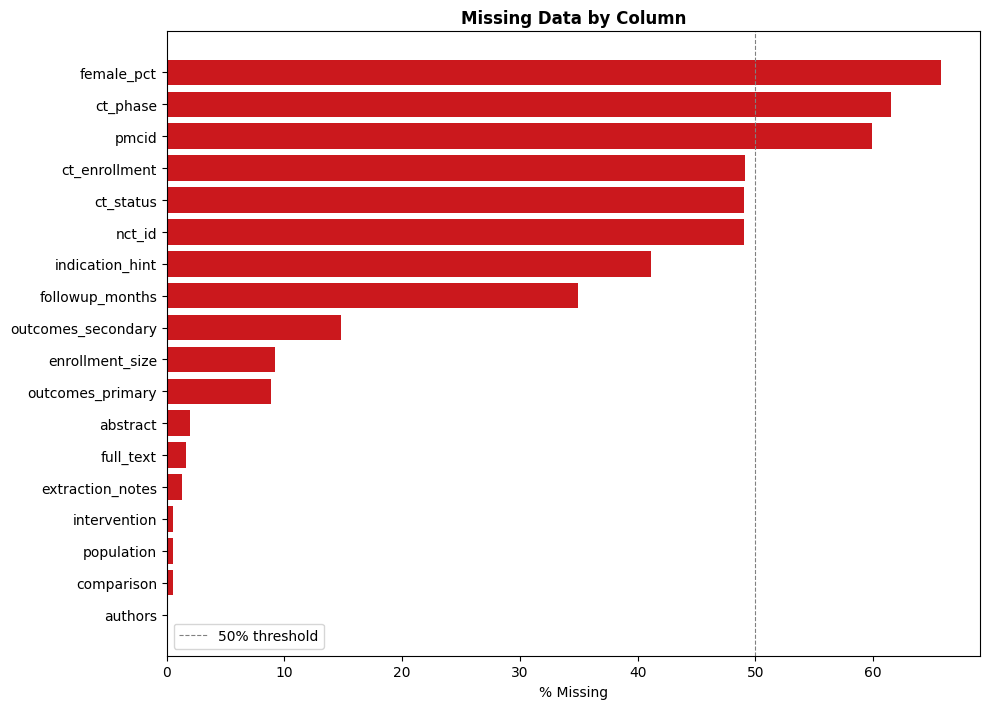

In [4]:
# ── Missing data overview ─────────────────────────────────────────────────────
missing = pd.DataFrame({
    "N Missing":  df.isna().sum(),
    "% Missing":  (df.isna().mean() * 100).round(1),
    "N Present":  df.notna().sum(),
}).sort_values("% Missing", ascending=False)

print("Missing data by column:")
display(missing)

# Bar chart of missingness
cols_with_missing = missing[missing["N Missing"] > 0]
if len(cols_with_missing):
    fig, ax = plt.subplots(figsize=(10, max(3, len(cols_with_missing) * 0.4)))
    ax.barh(cols_with_missing.index[::-1], cols_with_missing["% Missing"][::-1], color="#cb181d")
    ax.set_xlabel("% Missing")
    ax.set_title("Missing Data by Column", fontweight="bold")
    ax.axvline(50, color="gray", linestyle="--", linewidth=0.8, label="50% threshold")
    ax.legend()
    plt.tight_layout()
    plt.show()

In [5]:
# ── Sample rows ───────────────────────────────────────────────────────────────
print("First 5 rows (key columns):")
key_cols = [c for c in ["drug_name", "indication_clean", "comparator_type",
                         "female_pct", "enrollment_size", "follow_up_duration",
                         "women_only_trial", "sex_stratified_outcomes"] if c in df.columns]
display(df[key_cols].head())

First 5 rows (key columns):


,drug_name,indication_clean,comparator_type,female_pct,enrollment_size,follow_up_duration,women_only_trial,sex_stratified_outcomes
0,Other/NR,Obesity,Placebo,0.0,8.0,8 hours,False,False
1,Other/NR,Type 2 Diabetes,Placebo,NaN,6.0,48 hours,False,False
2,Other/NR,Other/NR,Placebo,NaN,8.0,NR,False,False
3,Other/NR,Type 2 Diabetes,Dose Comparison,NaN,15.0,4 hours,False,False
4,Other/NR,Other/NR,Placebo,0.0,6.0,6 hours,False,False


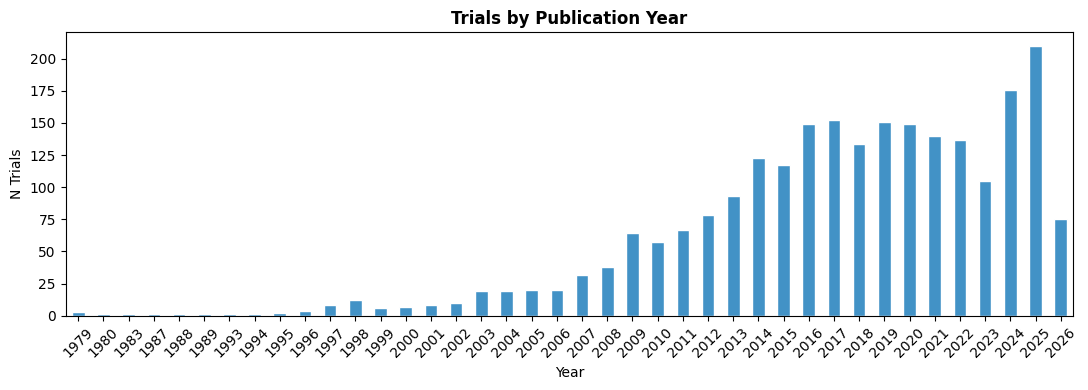

Year range: 1979 – 2026   |   Median: 2018


In [6]:
# ── Publication year distribution ─────────────────────────────────────────────
if "year" in df.columns:
    year_s = pd.to_numeric(df["year"], errors="coerce").dropna()
    fig, ax = plt.subplots(figsize=(11, 4))
    year_s.value_counts().sort_index().plot(kind="bar", ax=ax, color="#4292c6", edgecolor="white")
    ax.set_title("Trials by Publication Year", fontweight="bold")
    ax.set_xlabel("Year")
    ax.set_ylabel("N Trials")
    ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.show()
    print(f"Year range: {int(year_s.min())} – {int(year_s.max())}   |   Median: {int(year_s.median())}")

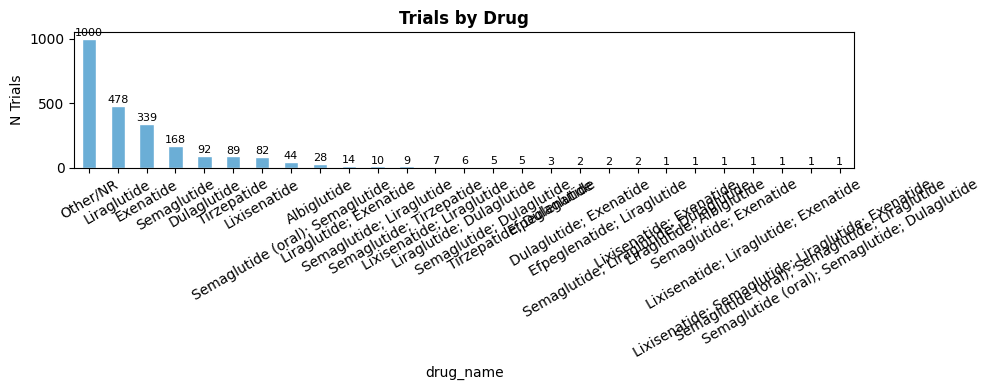

drug_name
Other/NR                                             1000
Liraglutide                                           478
Exenatide                                             339
Semaglutide                                           168
Dulaglutide                                            92
Tirzepatide                                            89
Lixisenatide                                           82
Semaglutide (oral); Semaglutide                        44
Albiglutide                                            28
Liraglutide; Exenatide                                 14
Semaglutide; Liraglutide                               10
Semaglutide; Tirzepatide                                9
Lixisenatide; Liraglutide                               7
Liraglutide; Dulaglutide                                6
Semaglutide; Dulaglutide                                5
Tirzepatide; Dulaglutide                                5
Efpeglenatide                                           3
Dula

In [7]:
# ── Drug distribution ─────────────────────────────────────────────────────────
drug_col = col("drug")
if drug_col:
    drug_counts = df[drug_col].value_counts()
    fig, ax = plt.subplots(figsize=(10, 4))
    drug_counts.plot(kind="bar", ax=ax, color="#6baed6", edgecolor="white")
    ax.set_title("Trials by Drug", fontweight="bold")
    ax.set_ylabel("N Trials")
    ax.tick_params(axis="x", rotation=30)
    for bar in ax.patches:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                str(int(bar.get_height())), ha="center", va="bottom", fontsize=8)
    plt.tight_layout()
    plt.show()
    print(drug_counts.to_string())

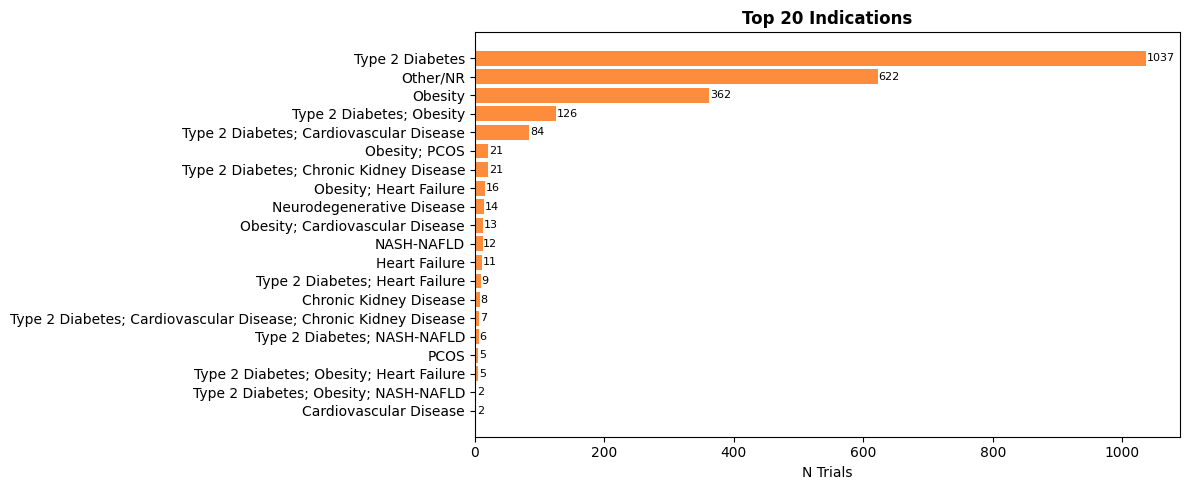

In [8]:
# ── Indication distribution (top 20) ─────────────────────────────────────────
ind_col = col("indication")
if ind_col:
    ind_counts = df[ind_col].value_counts().head(20)
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.barh(ind_counts.index[::-1], ind_counts.values[::-1], color="#fd8d3c")
    ax.set_title("Top 20 Indications", fontweight="bold")
    ax.set_xlabel("N Trials")
    for i, v in enumerate(ind_counts.values[::-1]):
        ax.text(v + 1, i, str(v), va="center", fontsize=8)
    plt.tight_layout()
    plt.show()

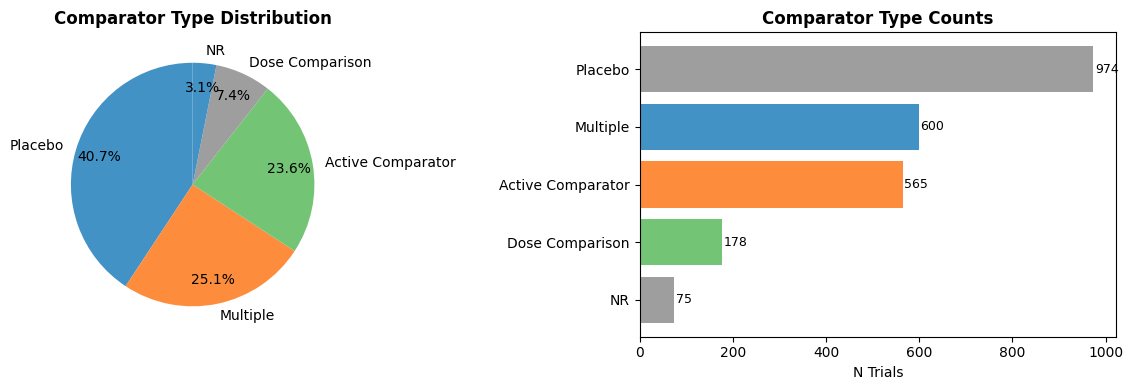

In [9]:
# ── Comparator type distribution ──────────────────────────────────────────────
comp_col = col("comparator_type")
if comp_col:
    comp_counts = df[comp_col].value_counts()
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].pie(comp_counts.values, labels=comp_counts.index, autopct="%1.1f%%",
                colors=["#4292c6", "#fd8d3c", "#74c476", "#9e9e9e"],
                startangle=90, pctdistance=0.8)
    axes[0].set_title("Comparator Type Distribution", fontweight="bold")

    axes[1].barh(comp_counts.index[::-1], comp_counts.values[::-1],
                 color=["#4292c6", "#fd8d3c", "#74c476", "#9e9e9e"][::-1])
    axes[1].set_xlabel("N Trials")
    axes[1].set_title("Comparator Type Counts", fontweight="bold")
    for i, v in enumerate(comp_counts.values[::-1]):
        axes[1].text(v + 3, i, str(v), va="center", fontsize=9)

    plt.tight_layout()
    plt.show()

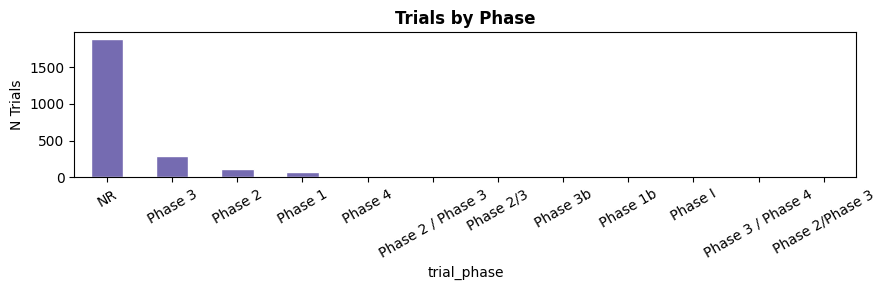

In [10]:
# ── Trial phase distribution ──────────────────────────────────────────────────
if "trial_phase" in df.columns:
    phase_counts = df["trial_phase"].value_counts()
    fig, ax = plt.subplots(figsize=(9, 3))
    phase_counts.plot(kind="bar", ax=ax, color="#756bb1", edgecolor="white")
    ax.set_title("Trials by Phase", fontweight="bold")
    ax.set_ylabel("N Trials")
    ax.tick_params(axis="x", rotation=30)
    plt.tight_layout()
    plt.show()

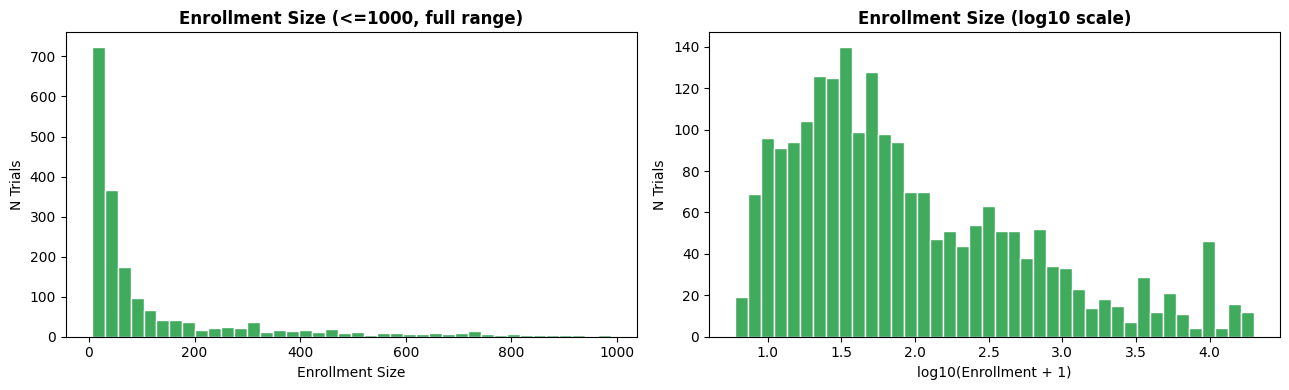

Enrollment — N: 2,173  |  Median: 54  |  Mean: 794  |  Max: 20000
Trials with n>=500:  400
Trials with n>=1000: 258


In [11]:
# ── Enrollment size distribution ──────────────────────────────────────────────
enr_col = col("enrollment")
if enr_col:
    enr = df[enr_col].dropna()
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    axes[0].hist(enr[enr <= 1000], bins=40, color="#41ab5d", edgecolor="white")
    axes[0].set_title("Enrollment Size (<=1000, full range)", fontweight="bold")
    axes[0].set_xlabel("Enrollment Size")
    axes[0].set_ylabel("N Trials")

    axes[1].hist(np.log10(enr + 1), bins=40, color="#41ab5d", edgecolor="white")
    axes[1].set_title("Enrollment Size (log10 scale)", fontweight="bold")
    axes[1].set_xlabel("log10(Enrollment + 1)")
    axes[1].set_ylabel("N Trials")

    plt.tight_layout()
    plt.show()

    print(f"Enrollment — N: {len(enr):,}  |  Median: {enr.median():.0f}  |  "
          f"Mean: {enr.mean():.0f}  |  Max: {enr.max():.0f}")
    print(f"Trials with n>=500:  {(enr>=500).sum():,}")
    print(f"Trials with n>=1000: {(enr>=1000).sum():,}")

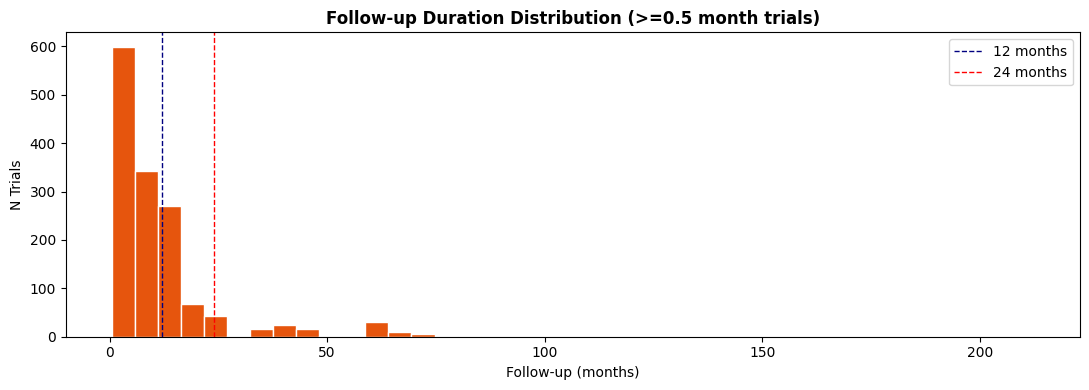

Follow-up — N parsed: 1,556  |  Median: 6.0 mo  |  Trials >=12 mo: 487  |  Trials >=24 mo: 148


In [12]:
# ── Follow-up duration distribution (parsed months) ───────────────────────────
if "followup_months" in df.columns:
    fu = df["followup_months"].dropna()
    # Exclude sub-day mechanistic trials (< 0.1 months) for the histogram
    fu_clinical = fu[fu >= 0.5]
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.hist(fu_clinical, bins=40, color="#e6550d", edgecolor="white")
    ax.set_title("Follow-up Duration Distribution (>=0.5 month trials)", fontweight="bold")
    ax.set_xlabel("Follow-up (months)")
    ax.set_ylabel("N Trials")
    ax.axvline(12, color="navy", linestyle="--", linewidth=1, label="12 months")
    ax.axvline(24, color="red",  linestyle="--", linewidth=1, label="24 months")
    ax.legend()
    plt.tight_layout()
    plt.show()
    print(f"Follow-up — N parsed: {len(fu):,}  |  Median: {fu.median():.1f} mo  |  "
          f"Trials >=12 mo: {(fu>=12).sum():,}  |  Trials >=24 mo: {(fu>=24).sum():,}")

SEX DATA COVERAGE
----------------------------------------
Female % reported:           818 / 2,392 trials (34.2%)
  Mean female %:             40.0%
  Trials >=50% female:       305
  Trials >=60% female:       206
  Trials 100% female:        80
Women-only trials:           80
Sex-stratified outcomes:     100


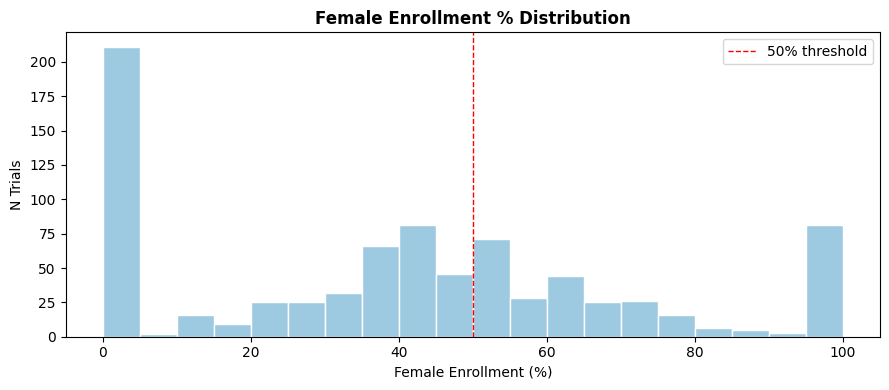

In [13]:
# ── Sex data coverage summary ─────────────────────────────────────────────────
female_col    = col("female_pct")
women_only_col = col("women_only")
sex_strat_col  = col("sex_stratified")

print("SEX DATA COVERAGE")
print("-" * 40)
if female_col:
    fp = df[female_col].dropna()
    print(f"Female % reported:           {len(fp):,} / {len(df):,} trials ({len(fp)/len(df)*100:.1f}%)")
    print(f"  Mean female %:             {fp.mean():.1f}%")
    print(f"  Trials >=50% female:       {(fp>=50).sum():,}")
    print(f"  Trials >=60% female:       {(fp>=60).sum():,}")
    print(f"  Trials 100% female:        {(fp==100).sum():,}")
if women_only_col:
    print(f"Women-only trials:           {int(df[women_only_col].sum()):,}")
if sex_strat_col:
    print(f"Sex-stratified outcomes:     {int(df[sex_strat_col].sum()):,}")

# Female % histogram
if female_col and len(fp) > 0:
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.hist(fp, bins=20, color="#9ecae1", edgecolor="white")
    ax.axvline(50, color="red", linestyle="--", linewidth=1, label="50% threshold")
    ax.set_title("Female Enrollment % Distribution", fontweight="bold")
    ax.set_xlabel("Female Enrollment (%)")
    ax.set_ylabel("N Trials")
    ax.legend()
    plt.tight_layout()
    plt.show()

In [14]:
# ── Numeric summary statistics ────────────────────────────────────────────────
numeric_cols = df.select_dtypes(include="number").columns.tolist()
if "followup_months" in df.columns:
    numeric_cols = [c for c in numeric_cols] + ["followup_months"]
    numeric_cols = list(dict.fromkeys(numeric_cols))  # deduplicate
print("Descriptive statistics (numeric columns):")
display(df[numeric_cols].describe().round(1))

Descriptive statistics (numeric columns):


,pmid,year,enrollment_size,female_pct,ct_enrollment,followup_months
count,2392.0,2392.0,2173.0,818.0,1218.0,1556.0
mean,29504705.3,2017.2,793.7,40.0,1699.2,9.9
std,7823670.1,6.5,2443.3,31.3,15144.6,13.8
min,91023.0,1979.0,5.0,0.0,0.0,0.0
25%,24393557.2,2014.0,20.0,0.0,36.0,2.8
50%,29706221.5,2018.0,54.0,40.6,102.5,6.0
75%,35840065.5,2022.0,295.0,60.0,469.0,12.0
max,42139606.0,2026.0,20000.0,100.0,451036.0,212.4


---
## Analysis 1: Women-Specific Evidence Landscape
Filter to high female-enrollment trials (>=50% female); characterize available evidence; identify gaps.

In [15]:
female_col     = col("female_pct")
women_only_col = col("women_only")
sex_strat_col  = col("sex_stratified")

high_female = df[df[female_col] >= 50].copy()       if female_col     else pd.DataFrame()
women_only  = df[df[women_only_col] == True].copy() if women_only_col else pd.DataFrame()

print("=" * 55)
print("WOMEN-SPECIFIC EVIDENCE SUMMARY")
print("=" * 55)
print(f"  Total trials in database:              {len(df):,}")
print(f"  Female % reported for:                 {int(df[female_col].notna().sum()):,} trials")
print(f"  Trials with >=50% female enrollment:   {len(high_female):,}")
print(f"  Women-only trials:                     {len(women_only):,}")
if sex_strat_col:
    print(f"  Trials with sex-stratified outcomes:   {int(df[sex_strat_col].sum()):,}")

WOMEN-SPECIFIC EVIDENCE SUMMARY
  Total trials in database:              2,392
  Female % reported for:                 818 trials
  Trials with >=50% female enrollment:   305
  Women-only trials:                     80
  Trials with sex-stratified outcomes:   100


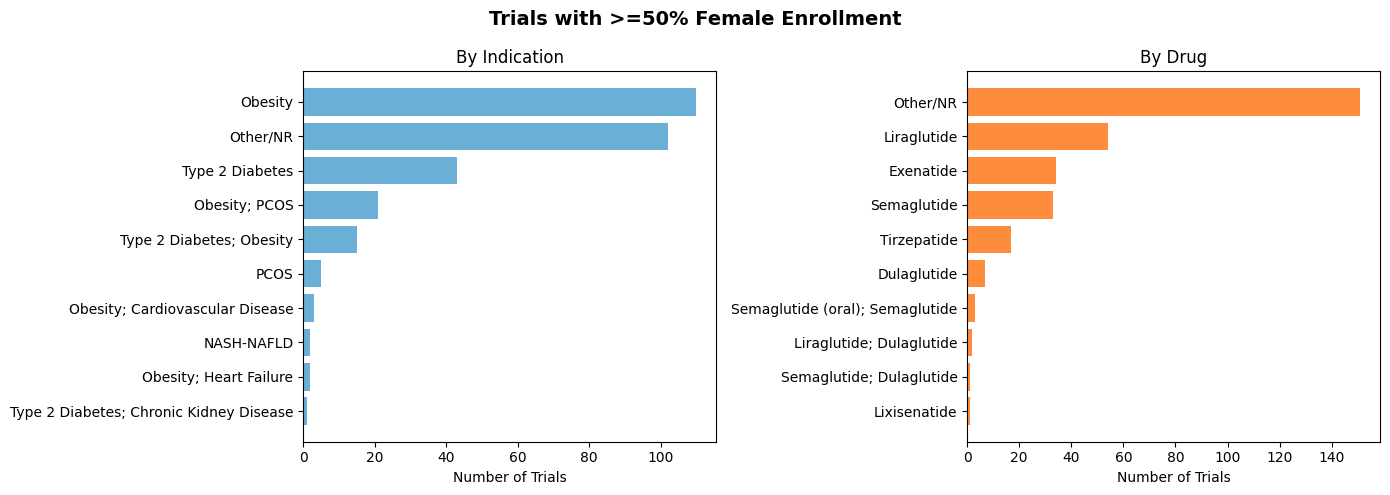


Drugs with NO trials at >=50% female enrollment:
  - Albiglutide
  - Dulaglutide; Exenatide
  - Efpeglenatide
  - Efpeglenatide; Liraglutide
  - Liraglutide; Albiglutide
  - Liraglutide; Exenatide
  - Lixisenatide; Exenatide
  - Lixisenatide; Liraglutide
  - Lixisenatide; Liraglutide; Exenatide
  - Lixisenatide; Semaglutide; Liraglutide; Exenatide
  - Semaglutide (oral); Semaglutide; Dulaglutide
  - Semaglutide (oral); Semaglutide; Liraglutide
  - Semaglutide; Exenatide
  - Semaglutide; Liraglutide; Dulaglutide
  - Tirzepatide; Dulaglutide


In [16]:
drug_col = col("drug")
ind_col  = col("indication")

if len(high_female) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle("Trials with >=50% Female Enrollment", fontsize=14, fontweight="bold")

    if ind_col:
        ind_counts = high_female[ind_col].value_counts().head(10)
        axes[0].barh(ind_counts.index[::-1], ind_counts.values[::-1], color="#6baed6")
        axes[0].set_title("By Indication")
        axes[0].set_xlabel("Number of Trials")

    if drug_col:
        drug_counts = high_female[drug_col].value_counts().head(10)
        axes[1].barh(drug_counts.index[::-1], drug_counts.values[::-1], color="#fd8d3c")
        axes[1].set_title("By Drug")
        axes[1].set_xlabel("Number of Trials")

    plt.tight_layout()
    plt.show()

    if drug_col:
        all_drugs    = set(df[drug_col].dropna().unique())
        female_drugs = set(high_female[drug_col].dropna().unique())
        gap_drugs    = all_drugs - female_drugs
        print("\nDrugs with NO trials at >=50% female enrollment:")
        for d in sorted(gap_drugs):
            print(f"  - {d}")
else:
    print("No high-female-enrollment trials found — check column name 'female_pct'")

---
## Analysis 2: Indication Landscape
Compare PICO patterns across obesity, T2D, cardiovascular, and NASH indications.

In [17]:
TARGET_INDICATIONS = {
    "Obesity":        "obesity",
    "T2D":            "type 2 diabetes|type 2|t2d",
    "Cardiovascular": "cardiovascular|cardiac|heart failure",
    "NASH":           "nash|nafld|mash|masld",
}

ind_col  = col("indication")
drug_col = col("drug")
enr_col  = col("enrollment")
comp_col = col("comparator_type")

summary_rows = []

for label, pattern in TARGET_INDICATIONS.items():
    subset = df[df[ind_col].str.contains(pattern, case=False, na=False, regex=True)] if ind_col else pd.DataFrame()
    row = {"Indication": label, "N Trials": len(subset)}
    if len(subset) == 0:
        summary_rows.append(row); continue

    if drug_col:
        vc = subset[drug_col].value_counts()
        row["Top Drug"] = vc.index[0] if len(vc) else "—"
        row["N Drugs"]  = subset[drug_col].nunique()
    if enr_col:
        row["Median Enrollment"] = int(subset[enr_col].median()) if not subset[enr_col].isna().all() else np.nan
    if "followup_months" in df.columns:
        fu = subset["followup_months"]
        row["Median Follow-up (mo)"] = round(fu.median(), 1) if not fu.isna().all() else np.nan
    if comp_col:
        row["Active Comparator"] = int(subset[comp_col].str.contains("Active Comparator", case=False, na=False).sum())
        row["Placebo"]           = int(subset[comp_col].str.contains("Placebo",           case=False, na=False).sum())
        row["Dose Comparison"]   = int(subset[comp_col].str.contains("Dose",              case=False, na=False).sum())

    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows).set_index("Indication")
print("INDICATION LANDSCAPE SUMMARY")
display(summary_df)

INDICATION LANDSCAPE SUMMARY


,N Trials,Top Drug,N Drugs,Median Enrollment,Median Follow-up (mo),Active Comparator,Placebo,Dose Comparison
Indication,,,,,,,,
Obesity,551,Other/NR,11,60,7.4,99,279,31
T2D,1300,Other/NR,27,117,6.0,404,452,77
Cardiovascular,152,Liraglutide,11,9340,24.0,10,129,1
NASH,22,Liraglutide,6,71,5.5,8,7,1


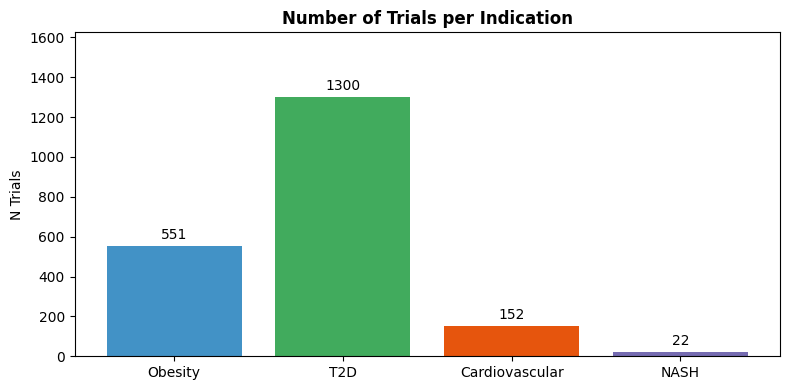

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
colors = ["#4292c6", "#41ab5d", "#e6550d", "#756bb1"]
bars = ax.bar(summary_df.index, summary_df["N Trials"], color=colors)
ax.bar_label(bars, padding=3)
ax.set_title("Number of Trials per Indication", fontweight="bold")
ax.set_ylabel("N Trials")
ax.set_ylim(0, summary_df["N Trials"].max() * 1.25)
plt.tight_layout()
plt.show()

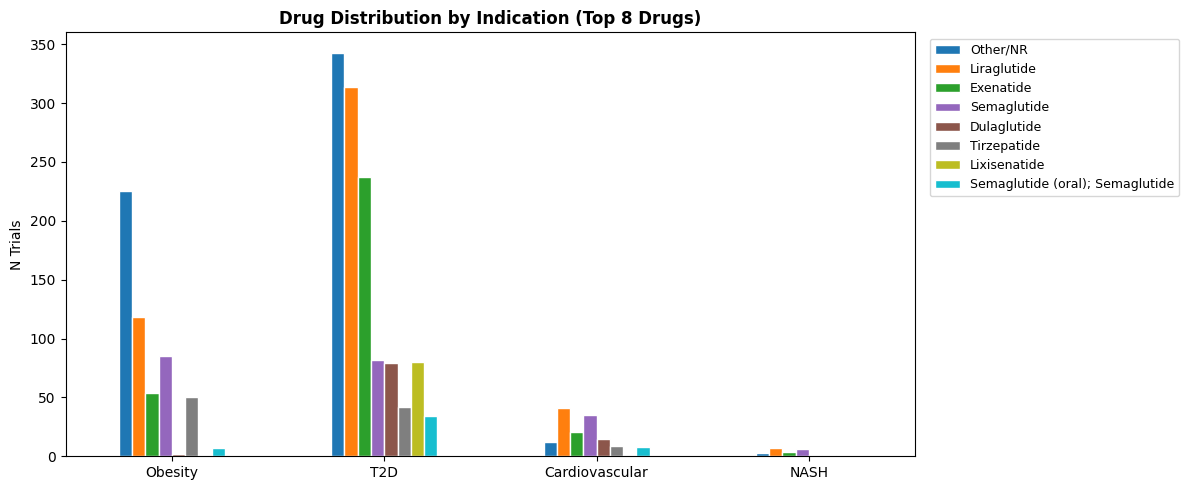

In [19]:
if drug_col and ind_col:
    top_drugs_global = df[drug_col].value_counts().head(8).index.tolist()
    pivot_data = {}
    for label, pattern in TARGET_INDICATIONS.items():
        subset = df[df[ind_col].str.contains(pattern, case=False, na=False, regex=True)]
        counts = subset[drug_col].value_counts()
        pivot_data[label] = {d: counts.get(d, 0) for d in top_drugs_global}

    pivot_df = pd.DataFrame(pivot_data).T
    pivot_df.plot(kind="bar", figsize=(12, 5), colormap="tab10", edgecolor="white")
    plt.title("Drug Distribution by Indication (Top 8 Drugs)", fontweight="bold")
    plt.ylabel("N Trials")
    plt.xticks(rotation=0)
    plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=9)
    plt.tight_layout()
    plt.show()

---
## Analysis 3: Comparator Gap Analysis
Which GLP-1 agents have head-to-head trial evidence vs. placebo-only?

In [20]:
# comparator_type values in this database: 'Placebo', 'Active Comparator', 'Dose Comparison', 'NR'
comp_col = col("comparator_type")
drug_col = col("drug")

if comp_col and drug_col:
    h2h_mask     = df[comp_col].str.contains("Active Comparator", case=False, na=False)
    placebo_mask = df[comp_col].str.contains("Placebo",           case=False, na=False)
    dose_mask    = df[comp_col].str.contains("Dose",              case=False, na=False)

    h2h     = df[h2h_mask]
    placebo = df[placebo_mask]

    print(f"Total trials:              {len(df):,}")
    print(f"Active comparator (H2H):   {len(h2h):,}")
    print(f"Placebo-controlled:        {len(placebo):,}")
    print(f"Dose comparison:           {int(dose_mask.sum()):,}")
    print(f"Not reported / other:      {int((~h2h_mask & ~placebo_mask & ~dose_mask).sum()):,}")

    h2h_drugs          = set(h2h[drug_col].dropna().unique())
    all_drugs          = set(df[drug_col].dropna().unique())
    placebo_only_drugs = all_drugs - h2h_drugs

    print("\nDrugs WITH active-comparator evidence:")
    for d in sorted(h2h_drugs):
        n = h2h[drug_col].value_counts().get(d, 0)
        print(f"  {d:<30}  ({n} trials)")

    print("\nDrugs with NO active-comparator evidence:")
    for d in sorted(placebo_only_drugs):
        print(f"  {d}")
else:
    print("comparator_type or drug_name column not found")

Total trials:              2,392
Active comparator (H2H):   565
Placebo-controlled:        974
Dose comparison:           178
Not reported / other:      675

Drugs WITH active-comparator evidence:
  Albiglutide                     (5 trials)
  Dulaglutide                     (26 trials)
  Exenatide                       (111 trials)
  Liraglutide                     (138 trials)
  Liraglutide; Albiglutide        (1 trials)
  Liraglutide; Dulaglutide        (4 trials)
  Liraglutide; Exenatide          (8 trials)
  Lixisenatide                    (27 trials)
  Lixisenatide; Exenatide         (1 trials)
  Lixisenatide; Liraglutide       (6 trials)
  Other/NR                        (171 trials)
  Semaglutide                     (27 trials)
  Semaglutide (oral); Semaglutide  (8 trials)
  Semaglutide (oral); Semaglutide; Dulaglutide  (1 trials)
  Semaglutide; Dulaglutide        (4 trials)
  Semaglutide; Exenatide          (1 trials)
  Semaglutide; Liraglutide        (2 trials)
  Semaglutide;

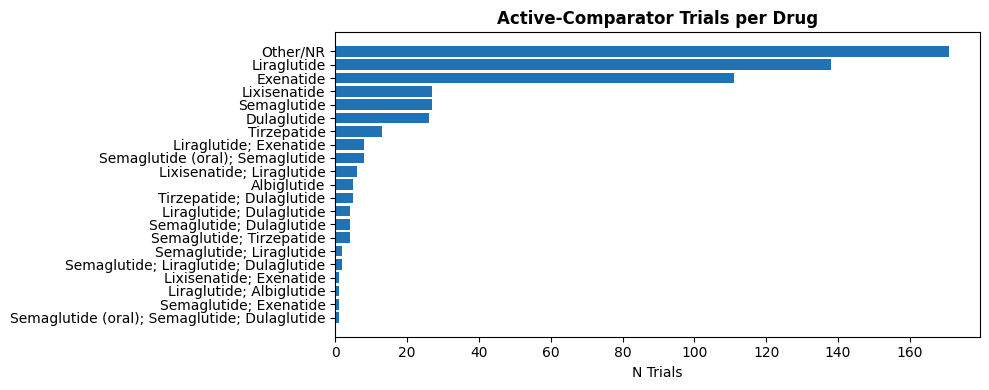

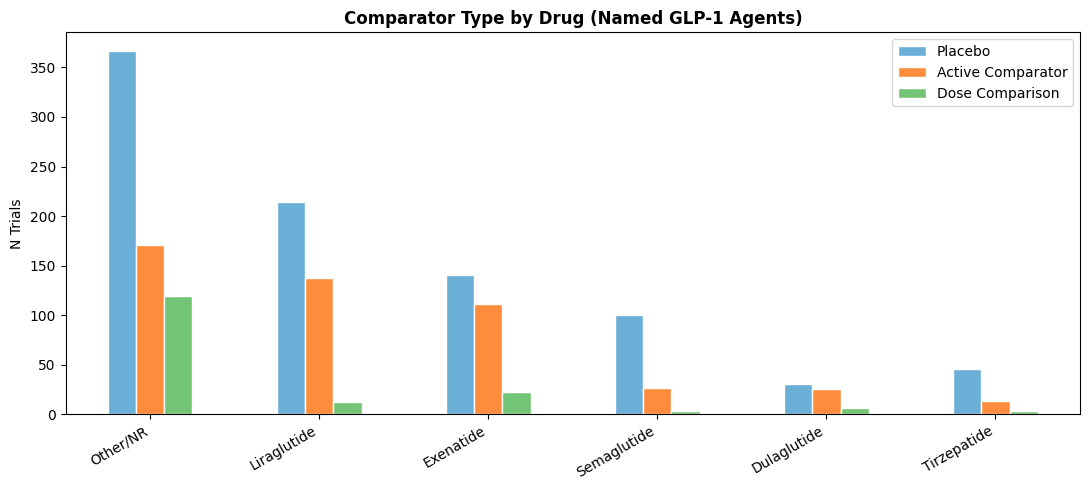

In [21]:
# H2H counts per named drug
if comp_col and drug_col and len(h2h) > 0:
    h2h_counts = h2h[drug_col].value_counts()
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.barh(h2h_counts.index[::-1], h2h_counts.values[::-1], color="#2171b5")
    ax.set_title("Active-Comparator Trials per Drug", fontweight="bold")
    ax.set_xlabel("N Trials")
    plt.tight_layout()
    plt.show()

# Stacked comparator breakdown for top 6 named drugs
if comp_col and drug_col:
    named_drugs = [d for d in df[drug_col].value_counts().index
                   if d not in ('Other/Unknown', 'GLP-1 (unspecified)')][:6]
    comp_pivot = {}
    for drug in named_drugs:
        sub = df[df[drug_col] == drug]
        comp_pivot[drug] = {
            "Placebo":           int(sub[comp_col].str.contains("Placebo",           case=False, na=False).sum()),
            "Active Comparator": int(sub[comp_col].str.contains("Active Comparator", case=False, na=False).sum()),
            "Dose Comparison":   int(sub[comp_col].str.contains("Dose",              case=False, na=False).sum()),
        }
    comp_df = pd.DataFrame(comp_pivot).T
    comp_df.plot(kind="bar", figsize=(11, 5), color=["#6baed6", "#fd8d3c", "#74c476"], edgecolor="white")
    plt.title("Comparator Type by Drug (Named GLP-1 Agents)", fontweight="bold")
    plt.ylabel("N Trials")
    plt.xticks(rotation=30, ha="right")
    plt.legend()
    plt.tight_layout()
    plt.show()

---
## Analysis 4: Outcome Heterogeneity
How many distinct definitions are used for weight loss, HbA1c, and MACE?

In [22]:
OUTCOME_TARGETS = {
    "Weight Loss": r"weight|bmi|body mass|waist",
    "HbA1c":       r"hba1c|glycat|a1c|hemoglobin a",
    "MACE":        r"mace|cardiovascular event|major adverse|cv event|cv death",
}

outcome_col = col("primary_outcome")   # outcomes_primary
heterogeneity_results = {}

if outcome_col:
    for label, pattern in OUTCOME_TARGETS.items():
        matches  = df[df[outcome_col].str.contains(pattern, case=False, na=False, regex=True)]
        raw_defs = matches[outcome_col].dropna().unique()
        heterogeneity_results[label] = {
            "n_trials":   len(matches),
            "n_distinct": len(raw_defs),
            "sample":     raw_defs[:5].tolist(),
        }

    for label, res in heterogeneity_results.items():
        print(f"\n{'='*60}")
        print(f"  {label}")
        print(f"{'='*60}")
        print(f"  Trials mentioning this outcome:  {res['n_trials']:,}")
        print(f"  Distinct raw definitions:        {res['n_distinct']:,}")
        print("  Sample definitions:")
        for d in res["sample"]:
            print(f"    - {str(d)[:115]}")
else:
    print("outcomes_primary column not found")


  Weight Loss
  Trials mentioning this outcome:  261
  Distinct raw definitions:        252
  Sample definitions:
    - Food intake per meal, weight loss
    - Glycemic control (fasting serum glucose, HbA1c), body weight
    - Body weight change
    - Glycaemic control (HbA1c change from baseline); body weight change from baseline
    - Body weight change over 6 months

  HbA1c
  Trials mentioning this outcome:  429
  Distinct raw definitions:        356
  Sample definitions:
    - HbA1c levels; capillary blood glucose (CBG) determinations
    - HbA1c after 12 weeks
    - Glycemic control (fasting serum glucose, HbA1c), body weight
    - HbA1c change from baseline at week 30
    - Change in A1C from baseline at week 30

  MACE
  Trials mentioning this outcome:  49
  Distinct raw definitions:        47
  Sample definitions:
    - Time to primary composite outcome of cardiovascular death, nonfatal myocardial infarction, or nonfatal stroke (MACE
    - First occurrence of any component of

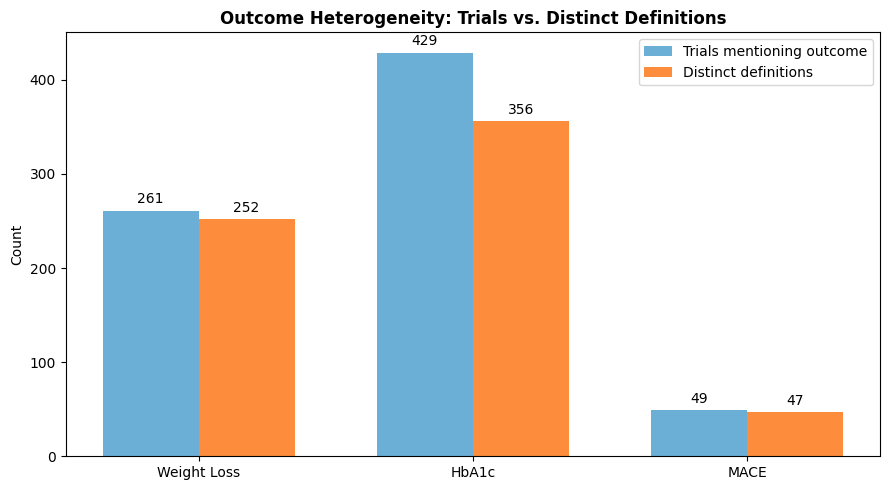

In [23]:
if heterogeneity_results:
    labels     = list(heterogeneity_results.keys())
    n_trials   = [heterogeneity_results[l]["n_trials"]  for l in labels]
    n_distinct = [heterogeneity_results[l]["n_distinct"] for l in labels]

    x = np.arange(len(labels))
    width = 0.35
    fig, ax = plt.subplots(figsize=(9, 5))
    b1 = ax.bar(x - width/2, n_trials,   width, label="Trials mentioning outcome", color="#6baed6")
    b2 = ax.bar(x + width/2, n_distinct, width, label="Distinct definitions",      color="#fd8d3c")
    ax.bar_label(b1, padding=3)
    ax.bar_label(b2, padding=3)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_title("Outcome Heterogeneity: Trials vs. Distinct Definitions", fontweight="bold")
    ax.set_ylabel("Count")
    ax.legend()
    plt.tight_layout()
    plt.show()

---
## Analysis 5: Evidence Sufficiency Scoring
For each simulation scenario, estimate whether evidence is sufficient for synthesis.

In [24]:
def score_sufficiency(subset):
    """
    Rule-based sufficiency score (0-100).

    Criteria                              Points
    ----------------------------------    ------
    >=5 trials                             30
    2-4 trials                             15
    >=1 large trial (enrollment >=500)     20
    >=1 active-comparator trial            20
    >=1 trial with >=12 months follow-up   15
    Sex-stratified outcomes present        15
    """
    score, reasons = 0, []
    n = len(subset)

    if n >= 5:
        score += 30; reasons.append(f">=5 trials (n={n})")
    elif n >= 2:
        score += 15; reasons.append(f"2-4 trials (n={n})")
    else:
        reasons.append(f"Fewer than 2 trials (n={n}) — likely insufficient")

    enr_c = col("enrollment")
    if enr_c and not subset[enr_c].isna().all():
        if (subset[enr_c] >= 500).any():
            score += 20; reasons.append(">=1 large trial (enrollment >=500)")

    comp_c = col("comparator_type")
    if comp_c:
        if subset[comp_c].str.contains("Active Comparator", case=False, na=False).any():
            score += 20; reasons.append("Active-comparator evidence present")

    if "followup_months" in subset.columns and not subset["followup_months"].isna().all():
        if (subset["followup_months"] >= 12).any():
            score += 15; reasons.append(">=1 trial with >=12 months follow-up")

    sx_c = col("sex_stratified")
    if sx_c and subset[sx_c].any():
        score += 15; reasons.append("Sex-stratified outcomes reported")

    verdict = "SUFFICIENT" if score >= 65 else ("PARTIAL" if score >= 35 else "INSUFFICIENT")
    return score, verdict, reasons

print("Sufficiency scoring function ready.")

Sufficiency scoring function ready.


In [25]:
SCENARIOS = [
    {"name": "Semaglutide for obesity",        "drug": "Semaglutide",  "indication": "obesity"},
    {"name": "Tirzepatide for obesity",         "drug": "Tirzepatide",  "indication": "obesity"},
    {"name": "Liraglutide for obesity",         "drug": "Liraglutide",  "indication": "obesity"},
    {"name": "Semaglutide for T2D",             "drug": "Semaglutide",  "indication": "type 2 diabetes|t2d"},
    {"name": "Liraglutide for T2D",             "drug": "Liraglutide",  "indication": "type 2 diabetes|t2d"},
    {"name": "Dulaglutide for T2D",             "drug": "Dulaglutide",  "indication": "type 2 diabetes|t2d"},
    {"name": "Any GLP-1 for cardiovascular",    "drug": None,           "indication": "cardiovascular|cardiac|heart failure"},
    {"name": "Any GLP-1 for NASH",              "drug": None,           "indication": "nash|nafld|mash|masld"},
    {"name": "Women-specific obesity evidence", "drug": None,           "indication": "obesity", "female_filter": True},
]

drug_col = col("drug")
ind_col  = col("indication")
fp_col   = col("female_pct")
results  = []

for sc in SCENARIOS:
    s = df.copy()
    if sc.get("drug") and drug_col:
        s = s[s[drug_col].str.contains(sc["drug"], case=False, na=False)]
    if sc.get("indication") and ind_col:
        s = s[s[ind_col].str.contains(sc["indication"], case=False, na=False, regex=True)]
    if sc.get("female_filter") and fp_col:
        s = s[s[fp_col] >= 50]

    score, verdict, reasons = score_sufficiency(s)
    results.append({"Scenario": sc["name"], "N Trials": len(s),
                    "Score": score, "Verdict": verdict, "_reasons": reasons})

results_df = pd.DataFrame(results)
display(results_df[["Scenario", "N Trials", "Score", "Verdict"]])

,Scenario,N Trials,Score,Verdict
0,Semaglutide for obesity,99,100,SUFFICIENT
1,Tirzepatide for obesity,53,100,SUFFICIENT
2,Liraglutide for obesity,124,100,SUFFICIENT
3,Semaglutide for T2D,140,100,SUFFICIENT
4,Liraglutide for T2D,354,100,SUFFICIENT
5,Dulaglutide for T2D,99,100,SUFFICIENT
6,Any GLP-1 for cardiovascular,152,100,SUFFICIENT
7,Any GLP-1 for NASH,22,65,SUFFICIENT
8,Women-specific obesity evidence,152,100,SUFFICIENT


In [26]:
for r in results:
    print(f"\n{'─'*60}")
    print(f"  {r['Scenario']}")
    print(f"  N Trials: {r['N Trials']}   Score: {r['Score']}/100   [{r['Verdict']}]")
    for reason in r["_reasons"]:
        print(f"     + {reason}")


────────────────────────────────────────────────────────────
  Semaglutide for obesity
  N Trials: 99   Score: 100/100   [SUFFICIENT]
     + >=5 trials (n=99)
     + >=1 large trial (enrollment >=500)
     + Active-comparator evidence present
     + >=1 trial with >=12 months follow-up
     + Sex-stratified outcomes reported

────────────────────────────────────────────────────────────
  Tirzepatide for obesity
  N Trials: 53   Score: 100/100   [SUFFICIENT]
     + >=5 trials (n=53)
     + >=1 large trial (enrollment >=500)
     + Active-comparator evidence present
     + >=1 trial with >=12 months follow-up
     + Sex-stratified outcomes reported

────────────────────────────────────────────────────────────
  Liraglutide for obesity
  N Trials: 124   Score: 100/100   [SUFFICIENT]
     + >=5 trials (n=124)
     + >=1 large trial (enrollment >=500)
     + Active-comparator evidence present
     + >=1 trial with >=12 months follow-up
     + Sex-stratified outcomes reported

─────────────

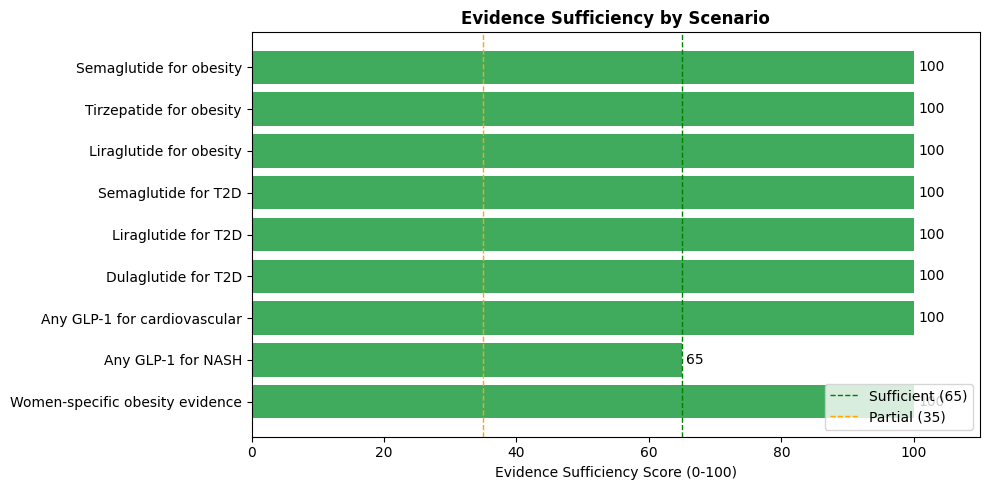

In [27]:
score_colors = [
    "#41ab5d" if s >= 65 else ("#fd8d3c" if s >= 35 else "#cb181d")
    for s in results_df["Score"]
]
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(results_df["Scenario"][::-1], results_df["Score"][::-1], color=score_colors[::-1])
ax.axvline(65, color="green",  linestyle="--", linewidth=1, label="Sufficient (65)")
ax.axvline(35, color="orange", linestyle="--", linewidth=1, label="Partial (35)")
ax.bar_label(bars, padding=3, fmt="%d")
ax.set_xlim(0, 110)
ax.set_xlabel("Evidence Sufficiency Score (0-100)")
ax.set_title("Evidence Sufficiency by Scenario", fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

---
## Export Phase 4 Results

In [28]:
export_df = results_df[["Scenario", "N Trials", "Score", "Verdict"]].copy()
export_df.to_excel("phase4_sufficiency_scores.xlsx", index=False)

if len(high_female) > 0:
    high_female.to_csv("phase4_high_female_trials.csv", index=False)

print("Phase 4 complete. Files exported:")
print("  phase4_sufficiency_scores.xlsx")
if len(high_female) > 0:
    print("  phase4_high_female_trials.csv")

Phase 4 complete. Files exported:
  phase4_sufficiency_scores.xlsx
  phase4_high_female_trials.csv
